# Exploration de METR-LA, pas à pas

Ce notebook reproduit l'analyse exploratoire du site et ajoute deux questions : **la corrélation décroît-elle avec la distance routière ?** et **quelle part de la variance est expliquée par l'identité (capteur × créneau) seule ?** Cette dernière borne ce qu'un modèle sans graphe peut capturer.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / 'pyproject.toml').exists():
    root = root.parent
os.chdir(root)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stforecast import viz
from stforecast.data import load_metr_la, load_adjacency, time_features
viz.setup()
df = load_metr_la()
ids, adj = load_adjacency()
df.shape, df.index.min(), df.index.max()

((34272, 207),
 Timestamp('2012-03-01 00:00:00'),
 Timestamp('2012-06-27 23:55:00'))

## 1. Statistiques de base

In [2]:
s = df.replace(0, np.nan)
pd.DataFrame({'vitesse moyenne (mph)': [s.stack().mean()],
              'écart-type': [s.stack().std()],
              '% manquants': [(df == 0).to_numpy().mean() * 100],
              'capteurs > 20 % manquants': [((df == 0).mean() > 0.2).sum()]}).round(2)

,vitesse moyenne (mph),écart-type,% manquants,capteurs > 20 % manquants
0,58.459999,13.02,8.11,1


## 2. Corrélation en fonction de la distance routière

Si le graphe porte du signal, deux capteurs proches *sur la route* doivent être plus corrélés que deux capteurs lointains. On utilise les distances du dépôt DCRNN (`distances_la_2012.csv`).

In [3]:
dist = pd.read_csv('data/raw/distances_la_2012.csv', dtype={'from': str, 'to': str})
pos = {k: i for i, k in enumerate(ids)}
dist = dist[dist['from'].isin(pos) & dist['to'].isin(pos)]
x = s.interpolate(limit_direction='both').diff().dropna().to_numpy()
corr = np.corrcoef(x.T)
dist['corr'] = [corr[pos[a], pos[b]] for a, b in zip(dist['from'], dist['to'])]
dist = dist[dist['from'] != dist['to']]
bins = pd.cut(dist['cost'] / 1609, [0, 1, 2, 4, 8])
g = dist.groupby(bins, observed=True)['corr'].agg(['median', 'count'])
g

,median,count
cost,,
"(0, 1]",0.173931,273
"(1, 2]",0.020645,735
"(2, 4]",0.009639,3221
"(4, 8]",0.006680,7317


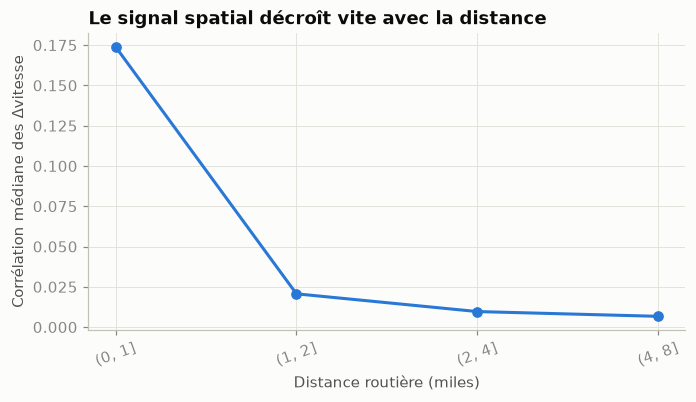

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(len(g)), g['median'], marker='o', color=viz.CAT[0])
ax.set_xticks(range(len(g)), [str(i) for i in g.index], rotation=20)
ax.set_xlabel('Distance routière (miles)')
ax.set_ylabel('Corrélation médiane des Δvitesse')
ax.set_title('Le signal spatial décroît vite avec la distance');

**Lecture :** la corrélation des variations (à 5 min, donc bruitées) est nettement plus élevée à moins d'un mile (≈ 0,17) qu'au-delà (≈ 0,01-0,02). Le signal spatial est **très local**. Une diffusion d'ordre 1-2 suffit, ce qui explique pourquoi des graphes profonds n'apportent que peu.

## 3. Quelle part de la variance l'identité explique-t-elle seule ?

On prédit chaque vitesse par la moyenne de son (capteur, créneau de la semaine) sur le train, puis on mesure le $R^2$ sur le test. C'est l'information d'**identité pure** que STID encode dans ses embeddings.

In [5]:
tod, dow = time_features(df.index)
slot = dow * 288 + tod
n_tr = int(len(df) * 0.7)
v = df.to_numpy()
tr = pd.DataFrame(v[:n_tr]).replace(0, np.nan).groupby(slot[:n_tr]).mean()
pred = tr.reindex(slot[n_tr:]).to_numpy()
y = v[n_tr:]
m = (y > 0) & ~np.isnan(pred)
r2 = 1 - ((pred[m] - y[m]) ** 2).sum() / ((y[m] - y[m].mean()) ** 2).sum()
print(f'R² identité seule (capteur × créneau) : {r2:.3f}')

R² identité seule (capteur × créneau) : 0.654


L'identité seule explique déjà une grande part de la variance. Le reste vient de la dynamique récente (la fenêtre d'entrée) et, éventuellement, des voisins (le graphe).

## 4. Indistinguabilité : combien de fenêtres jumelles ?

On tire des fenêtres (capteur, instant) au hasard. Parmi les paires dont les entrées sont quasi identiques (RMS < 1 mph), quelle part a des futurs qui divergent de plus de 10 mph à 60 minutes ?

In [6]:
rng = np.random.default_rng(1)
n = 6000
t = rng.integers(0, n_tr - 24, n)
k = rng.integers(0, v.shape[1], n)
xin = v[t[:, None] + np.arange(12), k[:, None]]
yout = v[t + 23, k]
ok = (xin > 0).all(1) & (yout > 0)
xin, yout = xin[ok], yout[ok]
d_in = np.sqrt(((xin[:, None] - xin[None]) ** 2).mean(-1))
iu = np.triu_indices(len(xin), 1)
close = d_in[iu] < 1.0
gap = np.abs(yout[:, None] - yout[None])[iu][close]
print(f'{close.sum():,} paires jumelles ; {(gap > 10).mean() * 100:.1f} % divergent de > 10 mph à 60 min')

35,735 paires jumelles ; 5.4 % divergent de > 10 mph à 60 min


Une petite fraction de jumelles diverge fortement. Ce sont **précisément les cas difficiles**, le début d'une congestion, où l'identité (quel capteur ? quelle heure ?) fait la différence entre « ça reste fluide » et « ça bouchonne ».